In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

Dataset Loaded Successfully!
Dataset Shape: (569, 30)
Target Shape: (569,)
Classes: ['malignant' 'benign']

Training Data: (455, 30)
Testing Data: (114, 30)

Decision Tree Model Trained Successfully!

========== ACCURACY ==========
Training Accuracy: 99.34 %
Testing Accuracy: 92.11 %

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

   malignant       0.87      0.93      0.90        42
      benign       0.96      0.92      0.94        72

    accuracy                           0.92       114
   macro avg       0.91      0.92      0.92       114
weighted avg       0.92      0.92      0.92       114



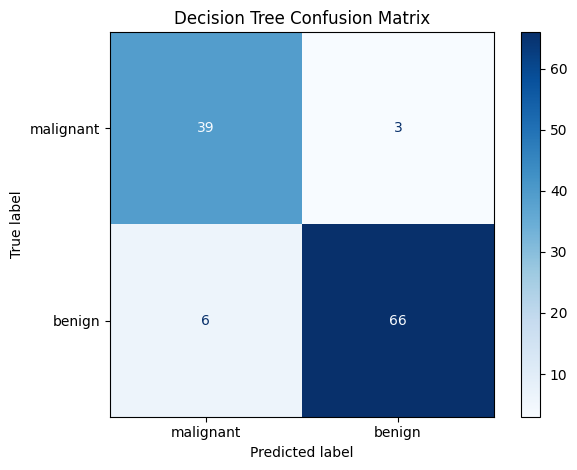

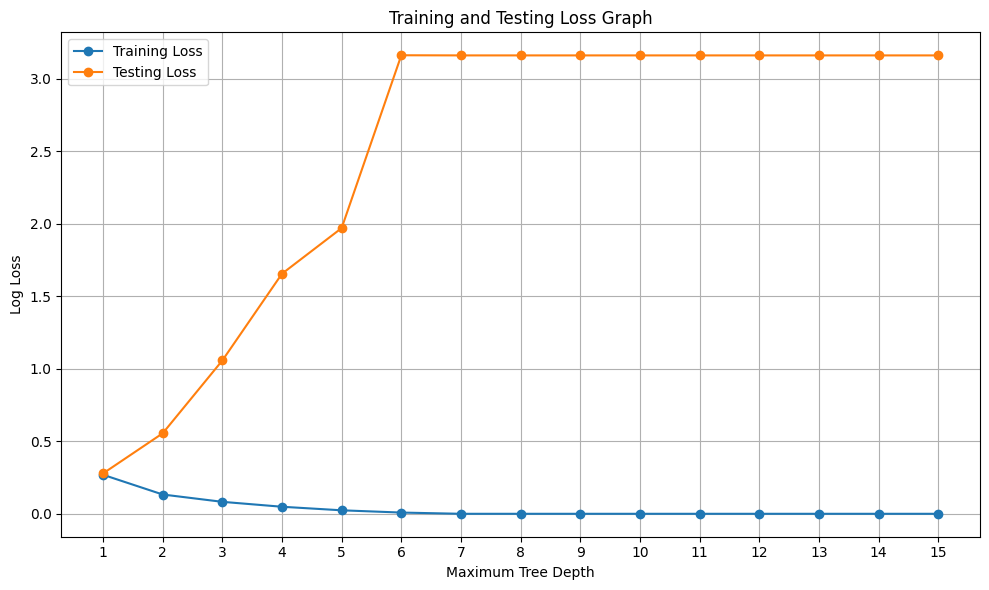


Model Saved Successfully!
Saved Location: /kaggle/working/decision_tree_model.joblib

Saved Model Loaded Successfully!
Accuracy of Loaded Model: 92.11 %

========== SAMPLE PREDICTION ==========
Predicted Class: malignant
Actual Class: malignant

Prediction Probabilities:
malignant : 100.0 %
benign : 0.0 %

========== DEPLOYMENT RESULT ==========
{'prediction': np.str_('malignant'), 'probabilities': {np.str_('malignant'): 1.0, np.str_('benign'): 0.0}}

========== PROJECT COMPLETED ==========
Model File: decision_tree_model.joblib
Loss Graph: training_testing_loss.png
Training Accuracy: 99.34 %
Testing Accuracy: 92.11 %


In [2]:

# ==========================================
# DECISION TREE MACHINE LEARNING PROJECT
# ==========================================

# Step 1: Import Libraries
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    log_loss,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Step 2: Load Dataset
data = load_breast_cancer()

X = pd.DataFrame(
    data.data,
    columns=data.feature_names
)

y = data.target

print("Dataset Loaded Successfully!")
print("Dataset Shape:", X.shape)
print("Target Shape:", y.shape)
print("Classes:", data.target_names)

# Step 3: Split Dataset into Training and Testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Data:", X_train.shape)
print("Testing Data:", X_test.shape)

# Step 4: Implement Decision Tree Model
model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    random_state=42
)

# Step 5: Train Model
model.fit(X_train, y_train)

print("\nDecision Tree Model Trained Successfully!")

# Step 6: Make Predictions
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

# Step 7: Calculate Accuracy
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print("\n========== ACCURACY ==========")
print("Training Accuracy:", round(train_accuracy * 100, 2), "%")
print("Testing Accuracy:", round(test_accuracy * 100, 2), "%")

# Step 8: Classification Report
print("\n========== CLASSIFICATION REPORT ==========")

print(classification_report(
    y_test,
    y_test_pred,
    target_names=data.target_names
))

# Step 9: Confusion Matrix
cm = confusion_matrix(y_test, y_test_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=data.target_names
).plot(cmap="Blues")

plt.title("Decision Tree Confusion Matrix")
plt.tight_layout()
plt.show()

# Step 10: Calculate Training and Testing Loss
depths = range(1, 16)

train_losses = []
test_losses = []

for depth in depths:

    temp_model = DecisionTreeClassifier(
        criterion="gini",
        max_depth=depth,
        random_state=42
    )

    temp_model.fit(X_train, y_train)

    train_prob = temp_model.predict_proba(X_train)
    test_prob = temp_model.predict_proba(X_test)

    train_loss = log_loss(
        y_train,
        train_prob,
        labels=[0, 1]
    )

    test_loss = log_loss(
        y_test,
        test_prob,
        labels=[0, 1]
    )

    train_losses.append(train_loss)
    test_losses.append(test_loss)

# Step 11: Plot Loss Graph
plt.figure(figsize=(10, 6))

plt.plot(
    list(depths),
    train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    list(depths),
    test_losses,
    marker="o",
    label="Testing Loss"
)

plt.xlabel("Maximum Tree Depth")
plt.ylabel("Log Loss")
plt.title("Training and Testing Loss Graph")
plt.xticks(list(depths))
plt.legend()
plt.grid(True)
plt.tight_layout()

# Save graph
plt.savefig(
    "/kaggle/working/training_testing_loss.png",
    dpi=150
)

plt.show()

# Step 12: Save the Trained Model
os.makedirs("/kaggle/working", exist_ok=True)

model_path = "/kaggle/working/decision_tree_model.joblib"

joblib.dump(model, model_path)

print("\nModel Saved Successfully!")
print("Saved Location:", model_path)

# Step 13: Load the Saved Model
loaded_model = joblib.load(model_path)

print("\nSaved Model Loaded Successfully!")

# Step 14: Test the Loaded Model
y_saved_pred = loaded_model.predict(X_test)

saved_accuracy = accuracy_score(
    y_test,
    y_saved_pred
)

print(
    "Accuracy of Loaded Model:",
    round(saved_accuracy * 100, 2),
    "%"
)

# Step 15: Predict a New Sample
sample = X_test.iloc[[0]]

prediction = loaded_model.predict(sample)[0]
probabilities = loaded_model.predict_proba(sample)[0]

print("\n========== SAMPLE PREDICTION ==========")

print(
    "Predicted Class:",
    data.target_names[prediction]
)

print(
    "Actual Class:",
    data.target_names[y_test[0]]
)

print("\nPrediction Probabilities:")

for class_name, probability in zip(
    data.target_names,
    probabilities
):
    print(class_name, ":", round(probability * 100, 2), "%")

# Step 16: Deployment Prediction Function
def predict_new_data(features):

    # Convert input features into a DataFrame
    input_data = pd.DataFrame(
        [features],
        columns=data.feature_names
    )

    # Check input data
    if input_data.isnull().any().any():
        raise ValueError("Please provide all feature values.")

    # Make prediction
    prediction = loaded_model.predict(input_data)[0]
    probabilities = loaded_model.predict_proba(input_data)[0]

    result = {
        "prediction": data.target_names[prediction],
        "probabilities": {
            name: float(probability)
            for name, probability in zip(
                data.target_names,
                probabilities
            )
        }
    }

    return result

# Step 17: Test Deployment Function
new_sample = X_test.iloc[0].tolist()

result = predict_new_data(new_sample)

print("\n========== DEPLOYMENT RESULT ==========")
print(result)

# Step 18: Show Saved Files
print("\n========== PROJECT COMPLETED ==========")
print("Model File: decision_tree_model.joblib")
print("Loss Graph: training_testing_loss.png")
print("Training Accuracy:", round(train_accuracy * 100, 2), "%")
print("Testing Accuracy:", round(test_accuracy * 100, 2), "%")
